In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns
from matplotlib.ticker import MaxNLocator
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

import os
import sys

# --- Make project root importable so `from Utils...` works ---
synenergy_root = os.path.abspath(os.path.join(os.getcwd(), "..", "SynEnergy"))
if synenergy_root not in sys.path:
    sys.path.insert(0, synenergy_root)

import torch
from Utils.context_fid import Context_FID
from Utils.predictive_metric import predictive_score_metrics
import Utils.extreme_anomaly_metric as extreme_anomaly_metric
from Utils.extreme_anomaly_metric import (
    extreme_anomaly_score_metrics,
    extreme_reconstruction_score_metrics,
)


pd.set_option("display.max_rows", None)         # Show all rows
pd.set_option("display.max_columns", None)      # Show all columns
pd.set_option("display.width", None)            # No fixed-width wrap
pd.set_option("display.max_colwidth", None)     # Do not truncate cell values
pd.set_option("display.expand_frame_repr", False)  # Prefer single-line frames

In [80]:
ori = np.load(f'../SynEnergy/Data/Power/Tallahassee_seq_42_sample_69500.npy')

In [81]:
def visualize_samples(ori_data, gen_data, N=10, threshold=None, seed=None, tail="upper"):
    """
    Draw two figures from N random samples of original and generated data.
    
    Parameters:
    -----------
    ori_data : np.ndarray, shape (num_samples, seq_length, 1)
        Original data
    gen_data : np.ndarray, shape (num_samples, seq_length, 1)
        Generated data
    N : int, default=10
        Number of samples to draw
    threshold : float, optional
        Threshold; with tail highlights values > or < threshold
    seed : int, optional, default=None
        Random seed; None gives different draws each call.
        Integer seed makes results reproducible.
    tail : str, default "upper"
        "upper": upper tail, red above threshold (original behavior);
        "lower": lower tail, red below threshold.
    """
    tail = str(tail).strip().lower()
    if tail not in ("upper", "lower"):
        raise ValueError('tail must be "upper" or "lower"')

    if seed is not None:
        np.random.seed(seed)
    
    # Ensure 3D shape
    if ori_data.ndim == 2:
        ori_data = ori_data[:, :, np.newaxis]
    if gen_data.ndim == 2:
        gen_data = gen_data[:, :, np.newaxis]
    
    # Random N indices
    num_samples = min(ori_data.shape[0], gen_data.shape[0])
    N = min(N, num_samples)
    selected_indices = np.random.choice(num_samples, size=N, replace=False)
    
    # Selected samples
    ori_selected = ori_data[selected_indices, :, 0]  # (N, seq_length)
    gen_selected = gen_data[selected_indices, :, 0]   # (N, seq_length)
    
    seq_length = ori_selected.shape[1]
    time_steps = np.arange(seq_length)

    def _extreme_mask(values):
        if threshold is None:
            return None
        return values > threshold if tail == "upper" else values < threshold
    
    # Two figures
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    
    # Fig 1: original
    ax1 = axes[0]
    for i in range(N):
        values = ori_selected[i, :]
        mask_ext = _extreme_mask(values)
        if mask_ext is not None:
            ax1.plot(time_steps, values, alpha=0.6, linewidth=1.5, color='blue', label='Original' if i == 0 else '')
            if np.any(mask_ext):
                ax1.plot(time_steps[mask_ext], values[mask_ext], 'ro', markersize=4, alpha=0.8)
        else:
            ax1.plot(time_steps, values, alpha=0.6, linewidth=1.5, color='blue', label='Original' if i == 0 else '')
    
    if threshold is not None:
        ax1.axhline(y=threshold, color='red', linestyle='--', linewidth=2, alpha=0.7,
                    label=f'Threshold={threshold} ({tail})')
    
    ax1.set_xlabel('Time Step', fontsize=12)
    ax1.set_ylabel('Value', fontsize=12)
    ax1.set_title(f'Original Data (N={N} random samples)', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend(fontsize=10)
    
    # Fig 2: generated
    ax2 = axes[1]
    for i in range(N):
        values = gen_selected[i, :]
        mask_ext = _extreme_mask(values)
        if mask_ext is not None:
            ax2.plot(time_steps, values, alpha=0.6, linewidth=1.5, color='green', label='Generated' if i == 0 else '')
            if np.any(mask_ext):
                ax2.plot(time_steps[mask_ext], values[mask_ext], 'ro', markersize=4, alpha=0.8)
        else:
            ax2.plot(time_steps, values, alpha=0.6, linewidth=1.5, color='green', label='Generated' if i == 0 else '')
    
    if threshold is not None:
        ax2.axhline(y=threshold, color='red', linestyle='--', linewidth=2, alpha=0.7,
                    label=f'Threshold={threshold} ({tail})')
    
    ax2.set_xlabel('Time Step', fontsize=12)
    ax2.set_ylabel('Value', fontsize=12)
    ax2.set_title(f'Generated Data (N={N} random samples)', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend(fontsize=10)
    
    plt.tight_layout()
    plt.show()
    
    print(f"Selected sample indices: {selected_indices}")
    print(f"Original data shape: {ori_selected.shape}")
    print(f"Generated data shape: {gen_selected.shape}")
    if threshold is not None:
        if tail == "upper":
            ori_ext = np.sum(ori_selected > threshold)
            gen_ext = np.sum(gen_selected > threshold)
            label = "above"
        else:
            ori_ext = np.sum(ori_selected < threshold)
            gen_ext = np.sum(gen_selected < threshold)
            label = "below"
        print(f"Values {label} threshold ({threshold}), tail={tail}:")
        print(f"  Original: {ori_ext} / {ori_selected.size} ({100*ori_ext/ori_selected.size:.2f}%)")
        print(f"  Generated: {gen_ext} / {gen_selected.size} ({100*gen_ext/gen_selected.size:.2f}%)")

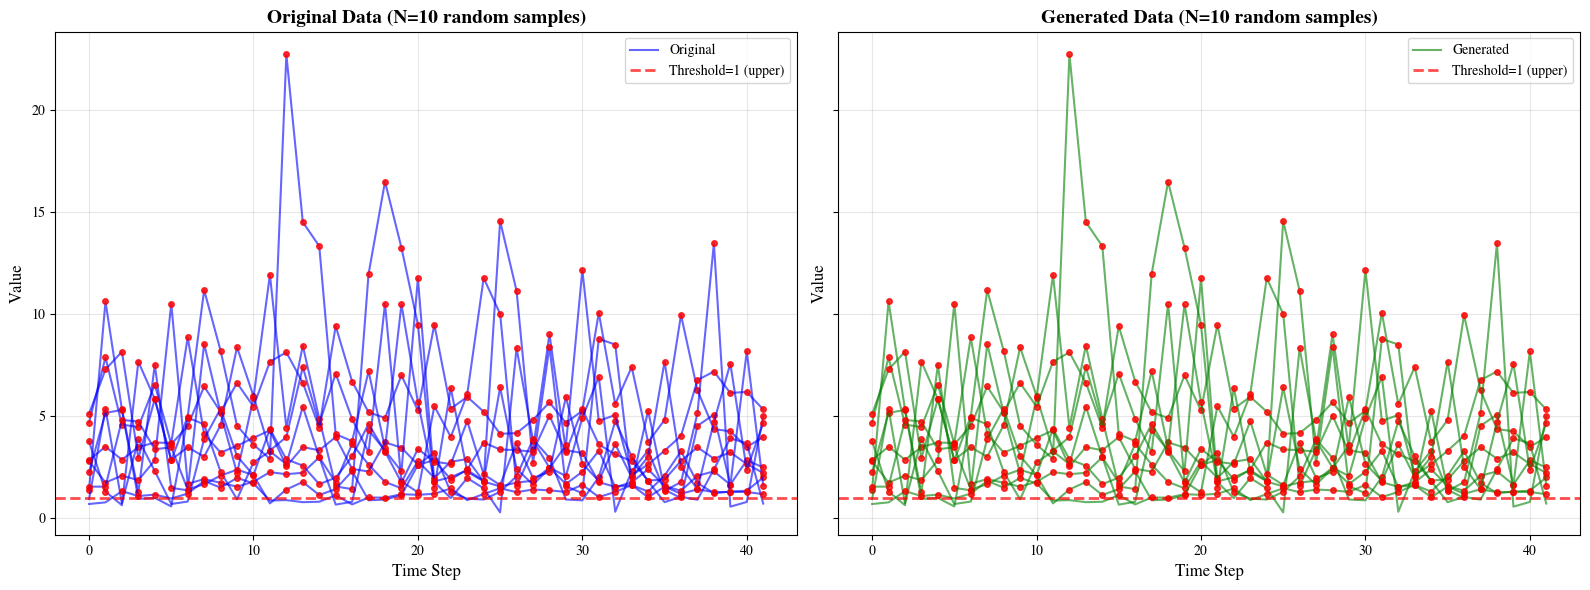

Selected sample indices: [20243 53125 39999 35732 61556 41907 35965 42186 60990 41532]
Original data shape: (10, 42)
Generated data shape: (10, 42)
Values above threshold (1), tail=upper:
  Original: 384 / 420 (91.43%)
  Generated: 384 / 420 (91.43%)


In [85]:
visualize_samples(ori, ori, N=10, threshold = 1, tail = 'upper')

In [86]:
def sample_data(data, compare=1000, random_state=2026):
    """Sample data along the first dimension.

    Args:
        data: input data with shape (N, seq_len, dim)
        compare: number of samples to keep
        random_state: random seed for reproducible sampling

    Returns:
        sampled_data: sampled data with shape (min(compare, N), seq_len, dim)
    """

    data = np.asarray(data)

    sample_no = min(compare, data.shape[0])

    rng = np.random.default_rng(random_state)
    idx = rng.permutation(data.shape[0])[:sample_no]

    sampled_data = data[idx]

    return sampled_data


def distribution_visualization(
    ori_data,
    generated_data,
    ori_label="Original",
    gen_label="Synthetic",
    title_suffix="Overall Generation",
    dataset_name=None,
    kde_xlim=None,
    random_state=2026,
):
    """PCA / t-SNE / KDE visualization in a 3x3 grid.

    This function uses all input data. If sampling is needed,
    call sample_data() before this function.

    Row 1: PCA
    Row 2: t-SNE
    Row 3: KDE

    Col 1: Original
    Col 2: Synthetic
    Col 3: Overlay
    """

    ori_data = np.asarray(ori_data)
    generated_data = np.asarray(generated_data)

    # 形状: (N, seq_len, dim)
    no, seq_len, dim = ori_data.shape
    gen_no = generated_data.shape[0]

    # 每个样本对特征维求均值: (N, seq_len, dim) -> (N, seq_len)
    prep_data = np.mean(ori_data, axis=2)
    prep_data_hat = np.mean(generated_data, axis=2)

    fig, axes = plt.subplots(3, 3, figsize=(18, 12))

    # =====================================================
    # Row 1: PCA
    # =====================================================
    pca = PCA(n_components=2)
    pca.fit(prep_data)

    pca_results = pca.transform(prep_data)
    pca_hat_results = pca.transform(prep_data_hat)

    # Original
    axes[0, 0].scatter(
        pca_results[:, 0],
        pca_results[:, 1],
        c="red",
        alpha=0.2,
        label=ori_label,
    )
    axes[0, 0].set_title(f"PCA | {ori_label}", fontsize=16)
    axes[0, 0].tick_params(axis="both", which="major", labelsize=12)

    # Synthetic
    axes[0, 1].scatter(
        pca_hat_results[:, 0],
        pca_hat_results[:, 1],
        c="blue",
        alpha=0.2,
        label=gen_label,
    )
    axes[0, 1].set_title(f"PCA | {gen_label}", fontsize=16)
    axes[0, 1].tick_params(axis="both", which="major", labelsize=12)

    # Overlay
    axes[0, 2].scatter(
        pca_results[:, 0],
        pca_results[:, 1],
        c="red",
        alpha=0.2,
        label=ori_label,
    )
    axes[0, 2].scatter(
        pca_hat_results[:, 0],
        pca_hat_results[:, 1],
        c="blue",
        alpha=0.2,
        label=gen_label,
    )
    axes[0, 2].set_title("PCA | Overlay", fontsize=16)
    axes[0, 2].legend(loc="upper right", fontsize=11, frameon=False)
    axes[0, 2].tick_params(axis="both", which="major", labelsize=12)

    # =====================================================
    # Row 2: t-SNE
    # =====================================================
    prep_data_final = np.concatenate((prep_data, prep_data_hat), axis=0)

    tsne = TSNE(
        n_components=2,
        verbose=1,
        perplexity=40,
        n_iter=300,
        random_state=random_state,
    )

    tsne_results = tsne.fit_transform(prep_data_final)

    tsne_ori = tsne_results[:no]
    tsne_hat = tsne_results[no:no + gen_no]

    # Original
    axes[1, 0].scatter(
        tsne_ori[:, 0],
        tsne_ori[:, 1],
        c="red",
        alpha=0.2,
        label=ori_label,
    )
    axes[1, 0].set_title(f"t-SNE | {ori_label}", fontsize=16)
    axes[1, 0].tick_params(axis="both", which="major", labelsize=12)

    # Synthetic
    axes[1, 1].scatter(
        tsne_hat[:, 0],
        tsne_hat[:, 1],
        c="blue",
        alpha=0.2,
        label=gen_label,
    )
    axes[1, 1].set_title(f"t-SNE | {gen_label}", fontsize=16)
    axes[1, 1].tick_params(axis="both", which="major", labelsize=12)

    # Overlay
    axes[1, 2].scatter(
        tsne_ori[:, 0],
        tsne_ori[:, 1],
        c="red",
        alpha=0.2,
        label=ori_label,
    )
    axes[1, 2].scatter(
        tsne_hat[:, 0],
        tsne_hat[:, 1],
        c="blue",
        alpha=0.2,
        label=gen_label,
    )
    axes[1, 2].set_title("t-SNE | Overlay", fontsize=16)
    axes[1, 2].legend(loc="upper right", fontsize=11, frameon=False)
    axes[1, 2].tick_params(axis="both", which="major", labelsize=12)

    # =====================================================
    # Row 3: KDE
    # =====================================================
    flat_ori = prep_data.flatten()
    flat_hat = prep_data_hat.flatten()

    # Original
    sns.kdeplot(
        flat_ori,
        linewidth=3,
        color="red",
        ax=axes[2, 0],
        label=ori_label,
    )
    axes[2, 0].set_title(f"KDE | {ori_label}", fontsize=16)
    axes[2, 0].set_xlabel("Data Value", fontsize=13)
    axes[2, 0].set_ylabel("Density", fontsize=13)
    axes[2, 0].tick_params(axis="both", which="major", labelsize=12)

    # Synthetic
    sns.kdeplot(
        flat_hat,
        linewidth=3,
        linestyle="--",
        color="blue",
        ax=axes[2, 1],
        label=gen_label,
    )
    axes[2, 1].set_title(f"KDE | {gen_label}", fontsize=16)
    axes[2, 1].set_xlabel("Data Value", fontsize=13)
    axes[2, 1].set_ylabel("Density", fontsize=13)
    axes[2, 1].tick_params(axis="both", which="major", labelsize=12)

    # Overlay
    sns.kdeplot(
        flat_ori,
        linewidth=3,
        color="red",
        ax=axes[2, 2],
        label=ori_label,
    )
    sns.kdeplot(
        flat_hat,
        linewidth=3,
        linestyle="--",
        color="blue",
        ax=axes[2, 2],
        label=gen_label,
    )
    axes[2, 2].set_title("KDE | Overlay", fontsize=16)
    axes[2, 2].set_xlabel("Data Value", fontsize=13)
    axes[2, 2].set_ylabel("Density", fontsize=13)
    axes[2, 2].legend(loc="upper right", fontsize=11, frameon=False)
    axes[2, 2].tick_params(axis="both", which="major", labelsize=12)

    if kde_xlim is not None:
        for c in range(3):
            axes[2, c].set_xlim(kde_xlim)

    # 总标题
    if dataset_name is not None:
        fig.suptitle(f"{dataset_name} | {title_suffix}", fontsize=20, y=1.02)
    else:
        fig.suptitle(title_suffix, fontsize=20, y=1.02)

    plt.tight_layout()

    plt.show()
    plt.close()

[t-SNE] Computing 121 nearest neighbors...
[t-SNE] Indexed 2000 samples in 0.001s...
[t-SNE] Computed neighbors for 2000 samples in 0.341s...
[t-SNE] Computed conditional probabilities for sample 1000 / 2000
[t-SNE] Computed conditional probabilities for sample 2000 / 2000
[t-SNE] Mean sigma: 0.000000
[t-SNE] KL divergence after 250 iterations with early exaggeration: 68.734428
[t-SNE] KL divergence after 300 iterations: 2.094944


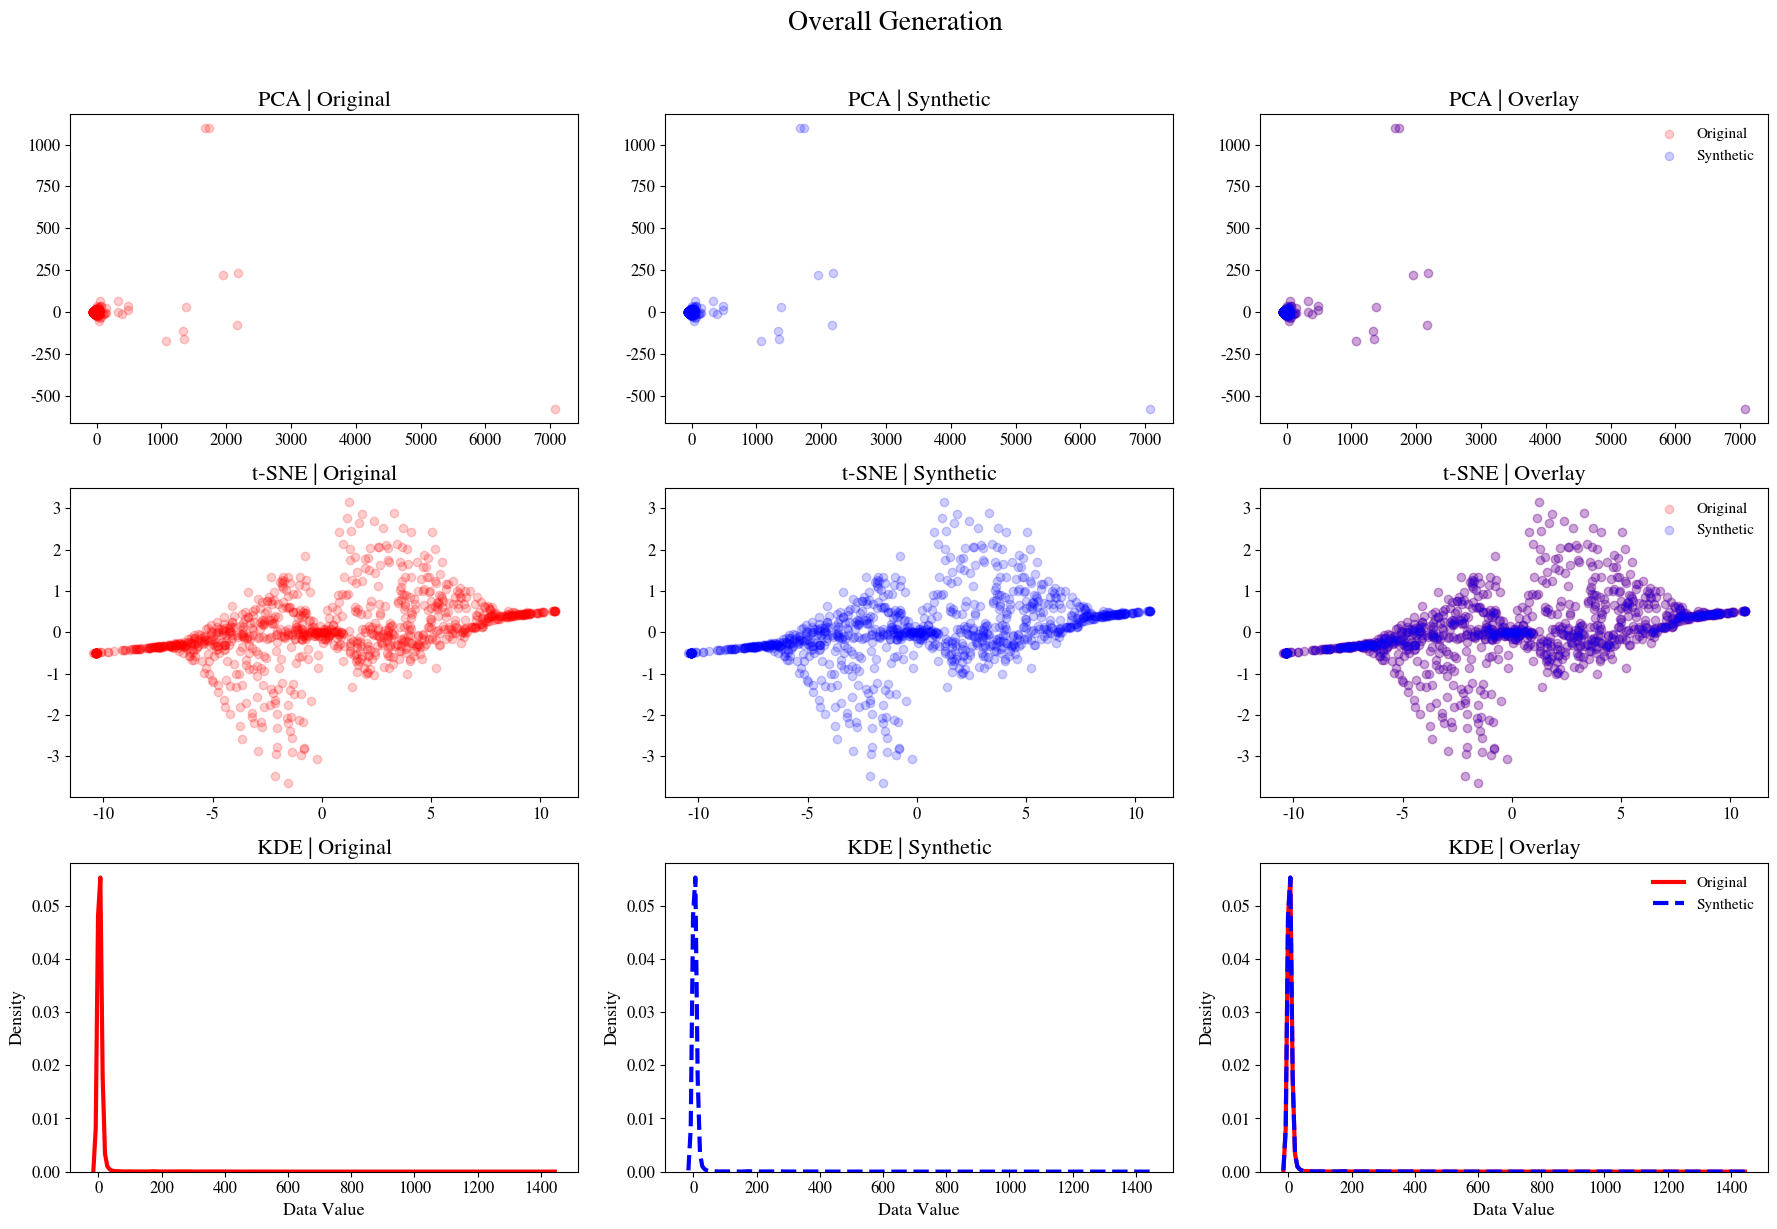

In [88]:
sample_oridata = sample_data(ori, compare=1000, random_state=42)
distribution_visualization(sample_oridata, sample_oridata, ori_label="Original", gen_label="Synthetic", title_suffix="Overall Generation", dataset_name=None, kde_xlim=None, random_state=42)